In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, differential_evolution, brentq
from functools import lru_cache
from pathlib import Path
from IPython.display import display


exportFigures = False
outDir = Path.cwd() / "outputs" / "ifp_translation"
figures = {}
check_results = {}

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "text.usetex": False})

## Helpers for checks and figures

`SOURCE_CHECKS` contains the statements being compared with the calculations. `check` prints the calculated value and a PASS or FAIL, then stores the result in `check_results`. Passing means the particular numerical comparison succeeded.


In [2]:
# Reference descriptions used by the numerical checks below.
SOURCE_CHECKS = {'retarder-no-loss': 'a retarder absorbs nothing: P(ICCD0) + P(ICCD1) = 1 for every delta and n', 'retarder-quarter-wave-held': 'a quarter-wave retardance per pass (half-wave per double pass) flips the sign of the leaked amplitude each cycle, so the slow component never transfers: P(ICCD1) = 1 and the expected number of passes is pi^2/8n = 0.0123 at n = 100', 'retarder-fast-axis-transfers': 'the fast component transfers like the no-sample case: P(ICCD0) = 1 with n passes', 'retarder-threshold': 'the retardance per pass at which the slow component is sorted to ICCD1 with probability 1/2 scales as 1.25/n', 'retarder-purity': 'the output polarisation stays pure at both ports (a retarder is unitary)', 'depolariser-sorted': 'a complete depolariser (q = 3/4) is sorted to ICCD1 with probability 0.945 at n = 100, since decoherence of the leaked amplitude inhibits the transfer like a which-path measurement', 'depolariser-more-passes': 'but a decoherer does not remove the leaked amplitude, so the photon passes the sample 5.6 times (q = 3/4) and 13 times (q = 0.3) at n = 100, more than the single pass of standard polarimetry', 'depolariser-signature': 'signature: the photon at ICCD1 keeps its input polarisation (purity 0.999 at q = 3/4, n = 100) while the photon at ICCD0 is fully depolarised (purity 0.5)', 'mixed-retardance-lowers-absorption': 'with Ts = 1/2 and theta = pi/8 at n = 100 the mean absorption over the six inputs falls from 0.035 (delta = 0) to 0.007 (pi/4) and 0.004 (pi/2): the phase on the absorbing axis adds to the Zeno inhibition; the same values hold at theta = pi/4', 'retardance-poorly-measured': 'the retardance of the absorbing axis is detected but poorly quantified: for (Tf, Ts, theta, delta) = (0.95, 0.5, pi/8, 0.6) the Cramer-Rao variance of delta is larger for the protocol than for a single pass, ratio single/protocol 0.23 (n = 10) and 0.004 (n = 100) per incident photon, 0.23 and 0.004 per absorbed photon', 'retardance-ratio-inverse': "the same per-absorbed ratios inverted, protocol/single, to four figures: 4.41 (n = 10) and 259 (n = 100), the paper's 4.4 and 260", 'axis-advantage-survives-retardance': 'with a lossless axis (Tf = 1) and retardance 0.6 on the absorbing axis, the axis orientation keeps its advantage: variance of theta per absorbed photon 11 times (n = 10) and 106 times (n = 100) smaller than for a single pass; per incident photon 3.9 and 4.3 times', 'retardance-Tf1': 'for the Tf = 1 sample the delta variance ratio per absorbed photon, protocol/single, is only 1.8 (n = 10) and 15 (n = 100)', 'fit-model-pure': 'the pure-state outcome probabilities used by the fit equal the density-matrix ones (to 10^-12) at the true and the single-pass test points', 'fit-point-conditioning': 'at the fit point (0.9, 0.4, pi/5, 0.6) the log10 condition number of the Fisher matrix is 3.1 (n = 10) and 4.6 (n = 100)', 'depolarisation-multipass-only': 'the protocol gives more information about q per incident photon (9.0 times at q = 0.1, n = 10) but not per pass through the sample (1.3 at n = 10, 0.31 at n = 100): a multi-pass gain, not an interaction-free one'}


def check(slug, computed, ok):
    status = bool(ok)
    check_results[slug] = {"check": slug, "stated": SOURCE_CHECKS[slug],
                           "computed": str(computed), "passed": status}
    print(f"{slug} | stated: {SOURCE_CHECKS[slug]} | computed: {computed} | {'PASS' if status else 'FAIL'}")


def note(slug, message):
    print(f"{slug} | note: {message}")


def finish_figure(name, fig):
    figures[name] = fig
    if exportFigures:
        outDir.mkdir(parents=True, exist_ok=True)
        fig.savefig(outDir / (name + ".pdf"), bbox_inches="tight")
    display(fig)
    plt.close(fig)


## Sample, input states and interferometer

The sample is described by a Jones matrix with intensity transmissions $T_f$ and $T_s$, orientation $\theta$ and relative phase $\delta$. The matrix uses $\sqrt{T_f}$ and $\sqrt{T_s}$ because it acts on field amplitudes. All angles are in radians.

The six inputs are H, V, D, A, R and L. They are measured in three alternative analyser bases: H/V, D/A and R/L. The joint basis is ordered as $|1,H\rangle, |1,V\rangle, |2,H\rangle, |2,V\rangle$.

`ubs` mixes the paths by $\pi/(4n)$ at each beam-splitter encounter. `usample` applies the sample only in path 1. `cycleK` combines two beam splitters and two sample passes, and `rhoOut` repeats the cycle $n$ times. `probs` returns the two detector probabilities; their sum is the survival probability.


In [3]:
# Identity and Pauli matrices acting on polarisation.
id2 = np.eye(2, dtype=complex)

sx = np.array([[0,1],[1,0]], complex)

sy = np.array([[0,-1j],[1j,0]], complex)

sz = np.diag([1.,-1.]).astype(complex)

# Projectors onto the sample path (1) and empty input path (2).
p1 = np.diag([1.,0.]); p2 = np.diag([0.,1.])

# Projectors onto the sample path (1) and empty input path (2).
p1 = np.diag([1.,0.]); p2 = np.diag([0.,1.])

# Rotate the polarisation axes or mix the two paths.
def rot(t):
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

# Build the sample response from intensity transmissions, orientation and phase.
def jones(t, tf, ts, d=0):
    # Complex square roots allow finite-difference evaluations at transmission boundaries.
    return rot(t) @ np.diag([np.sqrt(complex(tf)), np.sqrt(complex(ts))*np.exp(1j*d)]) @ rot(t).T

# Prepare six alternative input states; each vector has unit norm.
inputNames=['H','V','D','A','R','L']

inputs=dict(zip(inputNames,[np.array(x,complex)/np.linalg.norm(x) for x in [[1,0],[0,1],[1,1],[1,-1],[1,1j],[1,-1j]]]))

inputArray=np.array(list(inputs.values()))

# The three analyser choices, each with two orthogonal outcomes.
bases=np.array([[inputs['H'],inputs['V']],[inputs['D'],inputs['A']],[inputs['R'],inputs['L']]])

# The beam splitter changes the path but leaves polarisation unchanged.
def ubs(n): return np.kron(rot(np.pi/(4*n)),id2)

# Apply J in path 1 and the identity in path 2.
def usample(J): return np.kron(p1,J)+np.kron(p2,id2)

# Operators act right to left: beam splitter, sample, sample, beam splitter.
def cycleK(J,n):
    B=ubs(n); U=usample(J)
    return B@U@U@B

# Start in path 2 and keep the surviving state unnormalised.
def rhoOut(J,n,psi):
    v=np.linalg.matrix_power(cycleK(J,n),int(n))@np.r_[np.zeros(2),psi]
    return np.outer(v,v.conj())

# Extract one detector block: k=0 is ICCD0, k=1 is ICCD1.
def portRho(r,k): return r[2*k:2*k+2,2*k:2*k+2]

# Each block trace is the probability of reaching that detector.
def probs(J,n,psi):
    r=rhoOut(J,n,psi)
    return np.array([np.trace(portRho(r,k)).real for k in range(2)])

# Round reported values without changing the stored physical state.
r3=lambda x:np.round(x,3)

# Put all six inputs in path 2 as separate columns for efficient calculation.
initial_columns=np.vstack([np.zeros((2,6)),inputArray.T])


## Fisher information and variance bounds

`pure_outcomes` calculates the probabilities for all six inputs and three analyser bases. With no cycle count it describes a single pass; with a cycle count it describes the protocol. Each protocol setting has four detection outcomes, two at each port, plus absorption. A single pass has two analyser outcomes plus absorption.

`fisherMatrix` slightly changes each sample parameter to estimate how the probabilities respond. It uses those derivatives to form the Fisher matrix per incident photon, averaged equally over the 18 settings. Probabilities below the cutoff are omitted. 

The parameter order is $(T_f,T_s,\theta)$, with $\delta$ added when phase is included. The diagonal entries of the inverse Fisher matrix give the joint-estimation variance bounds per unit incident budget. For $N$ incident photons, the bound is $(F^{-1})_{ii}/N$.

`matrix_summary` compares information and variance bounds at equal incident or expected absorbed photon counts. The variance ratios are **single pass / protocol**, so values above 1 favour the protocol. `crbAbs` selects the axis-angle ratio at equal expected absorption. Repeated summaries are cached to avoid recalculating the same settings.


In [4]:
# Calculate every analyser outcome for either a single pass or n cycles.
def pure_outcomes(params,n=None):
    tf,ts,th,*phase=params
    J=jones(th,tf,ts,phase[0] if phase else 0)
    # No cycle count means the sample is encountered once.
    if n is None:
        v=inputArray@J.T
        pp=abs(np.einsum('bao,io->iba',bases.conj(),v))**2
    else:
        v=(np.linalg.matrix_power(cycleK(J,n),int(n))@initial_columns).T.reshape(6,2,2)
        pp=abs(np.einsum('bao,ipo->ibpa',bases.conj(),v))**2
        pp=pp.reshape(6,3,4)
    # Append the missing probability as the absorption outcome.
    return np.concatenate([pp,1-pp.sum(axis=-1,keepdims=True)],axis=-1)

# Estimate probability derivatives by symmetric finite differences.
def fisherMatrix(f,params,h=1e-6,cutoff=1e-15):
    params=np.array(params,float);p0=np.asarray(f(params))
    gradients=np.array([(f(params+h*e)-f(params-h*e))/(2*h) for e in np.eye(len(params))])
    # Exclude near-zero probabilities before dividing by them.
    mask=p0>cutoff
    # Flattening all equally weighted settings, then divide by their count.
    G=gradients[:,mask]
    settings=int(np.prod(p0.shape[:-1])) if p0.ndim>1 else 1
    return (G/p0[mask])@G.T/settings

# Fisher matrices and mean absorption, with equal weight for all 18 settings.
def fisherIFP(params,n):return fisherMatrix(lambda p:pure_outcomes(p,n),params)

def fisherSingle(params):return fisherMatrix(lambda p:pure_outcomes(p),params)

def absIFP(params,n):return np.mean(pure_outcomes(params,n)[...,-1])

def absSingle(params):return np.mean(pure_outcomes(params)[...,-1])

# Invert the full matrices so all fitted parameters are treated as unknown.
def matrix_summary(fi,fs,ai,ass):
    ci=np.linalg.inv(fi);cs=np.linalg.inv(fs)
    return {'F_IFP':fi,'F_single':fs,'Pabs_IFP':ai,'Pabs_single':ass,
            'diag ratio per incident (IFP/single)':np.diag(fi)/np.diag(fs),
            'diag ratio per absorbed (IFP/single)':np.diag(fi)/np.diag(fs)*ass/ai,
            'CRB variance ratio per incident (single/IFP)':np.diag(cs)/np.diag(ci),
            # Equal absorbed budgets introduce the factor Pabs_single / Pabs_IFP.
            'CRB variance ratio per absorbed (single/IFP)':np.diag(cs)/np.diag(ci)*ass/ai}

# Reuse results when the same sample and cycle count are needed again.
@lru_cache(maxsize=200)
def summary_cached(params,n):
    r=matrix_summary(fisherIFP(params,n),fisherSingle(params),absIFP(params,n),absSingle(params))
    r.update(params=params,n=n);return r

def summary(params,n):return summary_cached(tuple(params),int(n))

# Parameter index 2 is the sample orientation.
def crbAbs(r):return r['CRB variance ratio per absorbed (single/IFP)'][2]


## Comparing the axis-angle precision

This plot varies $T_s$ while holding $T_f=1$ and $\theta=\pi/8$, and compares 10 with 100 cycles.

The vertical axis is the single-pass variance bound divided by the protocol variance bound for the axis angle, at equal expected absorption. Both transmissions are also treated as unknown. A ratio above 1 means a smaller variance bound for the protocol; the dashed line marks equal performance. The logarithmic scale makes the range of ratios easier to see.


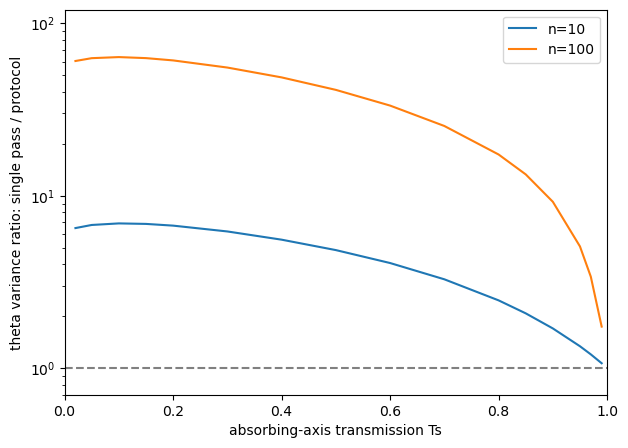

In [5]:
# Compare axis-angle variance bounds at equal expected absorption.
def axisGain(ts,n):return crbAbs(summary([1,ts,np.pi/8],n))
# Sweep the second-axis transmission; keep Tf=1 and theta=pi/8.
tsFig=np.array([.02,.05,.1,.15,.2,.3,.4,.5,.6,.7,.8,.85,.9,.95,.97,.99])
fig,ax=plt.subplots(figsize=(7,5))
# Plot the two cycle counts on a logarithmic vertical axis.
for n in [10,100]:ax.semilogy(tsFig,[axisGain(ts,n) for ts in tsFig],label=f'n={n}')
# A ratio of 1 means equal precision bounds.
ax.axhline(1,color='gray',ls='--');ax.set(xlim=(0,1),ylim=(.7,120),xlabel='absorbing-axis transmission Ts',ylabel='theta variance ratio: single pass / protocol')
ax.legend();finish_figure('mma_fisher_axis',fig)

## Samples that change phase or polarisation purity

These functions extend the calculation to a lossless retarder, a depolariser and a sample with both unequal transmission and a relative phase. A retarder adds phase $\delta$ to one polarisation component. The depolariser applies the identity with probability $1-q$ and each Pauli operation with probability $q/3$; $q=3/4$ gives a completely mixed polarisation state after a single sample pass.

The sample operations act in path 1 and leave the empty path unchanged. This specifies how the model treats coherence between the paths. `superoperators` writes the density-matrix evolution as a matrix multiplication, so `evolve` can calculate all $n$ cycles with one matrix power.

`evolve` returns the output state and two expected sample-pass counts. `passes_source` counts twice the sample-path population before the first pass in each cycle. `passes_corrected` counts the population before each pass separately, allowing for absorption on the first pass. 

`purity` describes the normalised polarisation at one detector: 1 means pure and 1/2 means completely mixed. It returns `NaN` if the port probability is too small. `kraus_outcomes` supplies the detection and absorption probabilities for the Fisher calculations, using the same six inputs and three analyser bases.


In [14]:
# Apply the weighted sample operations to one density matrix.
def samplePass(rho,kraus):
    return sum(w*(usample(K)@rho@usample(K).conj().T) for w,K in kraus)
# One complete cycle has two sample passes.
def cycle(rho,kraus,n):
    B=ubs(n);r=B@rho@B.conj().T
    return B@samplePass(samplePass(r,kraus),kraus)@B.conj().T

# Convert the operations into matrices acting on a flattened density matrix.
def superoperators(kraus,n):
    B=ubs(n);SB=np.kron(B,B.conj())
    SO=sum(w*np.kron(usample(K),usample(K).conj()) for w,K in kraus)
    return SB,SO,SB@SO@SO@SB

# Evolve the state and accumulate the expected sample-pass counts.
def evolve(psi,kraus,n):
    # Row-major vectorisation: vec(E rho E†) = (E ⊗ E*) vec(rho).
    rho=np.kron(p2,np.outer(psi,np.conj(psi)))
    SB,SO,SC=superoperators(kraus,n)
    # Augment the cycle with two linear counters, then raise once to n.
    pop=np.kron(p1,id2).T.ravel().real
    before=pop@SB
    aug=np.zeros((18,18),complex);aug[:16,:16]=SC
    # Row 16 uses the source count; row 17 counts before each pass separately.
    aug[16,:16]=2*before;aug[17,:16]=before+pop@SO@SB
    aug[16,16]=aug[17,17]=1
    v=np.linalg.matrix_power(aug,int(n))@np.r_[rho.ravel(),0,0]
    return v[:16].reshape(4,4),float(v[16].real),float(v[17].real)
# Separate the ICCD0 and ICCD1 polarisation blocks.
def ports(rho):return rho[:2,:2],rho[2:,2:]
# Normalise this port only when calculating its polarisation purity.
def purity(r):
    t=np.trace(r).real
    return np.trace((r/t)@(r/t)).real if t>1e-9 else np.nan

# Return P0, P1, the source pass count, and the two port purities.
def summaryRun(psi,kraus,n):
    rho,passes,_=evolve(psi,kraus,n);r0,r1=ports(rho)
    return np.array([np.trace(r0).real,np.trace(r1).real,passes,purity(r0),purity(r1)])

# Compute all input/analyser probabilities for the chosen sample model.
def kraus_outcomes(kraus,n=None):
    if n is None:
        rs=[sum(w*(K@np.outer(psi,psi.conj())@K.conj().T) for w,K in kraus) for psi in inputArray]
        pp=np.array([[[np.vdot(b,r@b).real for b in basis] for basis in bases] for r in rs])
    else:
        _,_,SC=superoperators(kraus,n);SN=np.linalg.matrix_power(SC,int(n))
        rs=[(SN@np.kron(p2,np.outer(psi,psi.conj())).ravel()).reshape(4,4) for psi in inputArray]
        pp=np.array([[[np.vdot(b,rp@b).real for rp in ports(r) for b in basis] for basis in bases] for r in rs])
    return np.concatenate([pp,1-pp.sum(axis=-1,keepdims=True)],axis=-1)
# Outcome probabilities for one input and analyser in the protocol.
def probsIFP4(kraus,n,psi,basis):
    rho=evolve(psi,kraus,n)[0]
    pp=np.array([np.vdot(b,r@b).real for r in ports(rho) for b in basis])
    return np.r_[pp,1-sum(pp)]
# The corresponding outcomes after one sample pass.
def probsSingle4(kraus,psi,basis):
    r=sum(w*(K@np.outer(psi,psi.conj())@K.conj().T) for w,K in kraus)
    pp=np.array([np.vdot(b,r@b).real for b in basis]);return np.r_[pp,1-sum(pp)]
# Use a derivative step of 1e-5 and an outcome cutoff of 1e-12.
def fisherAll(krausOf,params,n):return fisherMatrix(lambda p:kraus_outcomes(krausOf(p),n),params,h=1e-5,cutoff=1e-12)
def fisherAllSingle(krausOf,params):return fisherMatrix(lambda p:kraus_outcomes(krausOf(p)),params,h=1e-5,cutoff=1e-12)
# Average resource use over the six equally weighted input states.
def meanPasses(kraus,n):return np.mean([evolve(psi,kraus,n)[1] for psi in inputArray])
def meanAbs(kraus,n):return np.mean(kraus_outcomes(kraus,n)[...,-1])
def meanAbsSingle(kraus):return np.mean(kraus_outcomes(kraus)[...,-1])
# Lossless phase shift on the second polarisation axis.
def retarder(d):return [(1,np.diag([1,np.exp(1j*d)]))]
# Random Pauli model; q=3/4 gives complete single-pass depolarisation.
def depol(q):return [(1-q,id2),(q/3,sx),(q/3,sy),(q/3,sz)]
# A single Jones matrix combining unequal transmissions and phase.
def mixed(tf,ts,th,d):return [(1,jones(th,tf,ts,d))]
def mixedOf(params):return mixed(*params)

### Detector probabilities, sample passes and purity

The first table uses V input to test lossless retarders at several phase shifts and at 10 and 100 cycles. The checks confirm that no probability is absorbed and compare the output ports, sample-pass counts and polarisation purity. `brentq` finds the phase shift where the probability of reaching ICCD1 is 1/2.

The second table uses H input for several depolarisation strengths. It records the two detector probabilities, expected sample passes and purity at each port. These results are stored in `retarder_table` and `depol_table`.

Finally, `mixed_rows` records a sample with $T_f=1$, $T_s=0.5$ and $\theta=\pi/8$ at three phase shifts. Absorption and pass counts are averaged over all six inputs. The table includes both pass-count definitions and the single-pass absorption for comparison.


In [15]:
# Retarder results for V input: delta, n, P0, P1, passes, purity0, purity1.
retarder_table=[np.r_[d,n,summaryRun(inputs['V'],retarder(d),n)] for d in [0,.02,.1,.3,np.pi/4,np.pi/2] for n in [10,100]]
display(pd.DataFrame(retarder_table,columns=['delta','n','P0','P1','passes_source','purity0','purity1']))
# Checks probability conservation for the lossless retarder.
err=max(abs(1-sum(summaryRun(inputs['V'],retarder(d),n)[:2])) for d in [0,.1,np.pi/4,np.pi/2] for n in [10,100])
check('retarder-no-loss',err,err<1e-9)
# A pi/2 phase per pass becomes pi across the two passes in each cycle.
v=summaryRun(inputs['V'],retarder(np.pi/2),100)
check('retarder-quarter-wave-held',v[[1,2]],abs(v[1]-1)<1e-9 and abs(v[2]-np.pi**2/800)<1e-4)
v=summaryRun(inputs['H'],retarder(np.pi/2),100)
check('retarder-fast-axis-transfers',v[[0,2]],abs(v[0]-1)<1e-9)
# Finds the phase where half the incident photons reach ICCD1.
def pIccd1(d,n):return probs(jones(0,1,1,d),n,inputs['V'])[1]
thr=[(n,brentq(lambda d:pIccd1(d,n)-.5,.3/n,2/n)) for n in [10,30,100,300,1000]]
check('retarder-threshold',[(n,d,n*d) for n,d in thr],max(abs(n*d-1.2546) for n,d in thr)<.01)
# Check that the surviving polarisation at each port remains pure.
v=summaryRun(inputs['D'],retarder(.3),100)[[3,4]]
check('retarder-purity',v,max(abs(v-1))<1e-9)

# Repeats with a depolariser and H input.
depol_table=[np.r_[q,n,summaryRun(inputs['H'],depol(q),n)] for q in [.01,.1,.3,.75] for n in [10,100]]
display(pd.DataFrame(depol_table,columns=['q','n','P0','P1','passes_source','purity0','purity1']))
print('single-pass output purity:',[(q,purity(sum(w*K@np.outer(inputs['H'],inputs['H'].conj())@K.conj().T for w,K in depol(q)))) for q in [.01,.1,.3,.75]])
v=summaryRun(inputs['H'],depol(.75),100)
check('depolariser-sorted',v[1],abs(v[1]-.945)<.002)
vpasses=[v[2],summaryRun(inputs['H'],depol(.3),100)[2]]
check('depolariser-more-passes',vpasses,vpasses[0]>5 and vpasses[1]>12)
check('depolariser-signature',v[[3,4]],v[4]>.99 and abs(v[3]-.5)<.01)

# Averages the absorbing-retarder results over all six input states.
mixed_rows=[]
for d in [0,np.pi/4,np.pi/2]:
    for n in [10,100]:
        kr=mixed(1,.5,np.pi/8,d)
        # Count each sample encounter separately for the corrected column.
        corrected=np.mean([evolve(psi,kr,n)[2] for psi in inputArray])
        mixed_rows.append([d,n,meanAbs(kr,n),meanPasses(kr,n),corrected,meanAbsSingle(kr)])
display(pd.DataFrame(mixed_rows,columns=['delta','n','Pabs','passes_source','passes_corrected','Pabs_single']))
v=[meanAbs(mixed(1,.5,np.pi/8,d),100) for d in [0,np.pi/4,np.pi/2]]
# Compare two orientations to check the six-input average.
err=max(abs(meanAbs(mixed(1,.5,np.pi/8,d),100)-meanAbs(mixed(1,.5,np.pi/4,d),100)) for d in [0,np.pi/4,np.pi/2])
check('mixed-retardance-lowers-absorption',v,v[2]<v[1]<v[0] and err<1e-9)

retarder-no-loss | stated: a retarder absorbs nothing: P(ICCD0) + P(ICCD1) = 1 for every delta and n | computed: 2.220446049250313e-14 | PASS
retarder-quarter-wave-held | stated: a quarter-wave retardance per pass (half-wave per double pass) flips the sign of the leaked amplitude each cycle, so the slow component never transfers: P(ICCD1) = 1 and the expected number of passes is pi^2/8n = 0.0123 at n = 100 | computed: [1.       0.012337] | PASS
retarder-fast-axis-transfers | stated: the fast component transfers like the no-sample case: P(ICCD0) = 1 with n passes | computed: [  1. 100.] | PASS
retarder-threshold | stated: the retardance per pass at which the slow component is sorted to ICCD1 with probability 1/2 scales as 1.25/n | computed: [(10, 0.12509995032368545, 1.2509995032368546), (30, 0.04180597904472358, 1.2541793713417073), (100, 0.012545367278588822, 1.2545367278588822), (300, 0.004181893670421764, 1.2545681011265293), (1000, 0.0012545716693983073, 1.2545716693983073)] | PASS

,delta,n,P0,P1,passes_source,purity0,purity1
0,0.000000,10.0,1.000000e+00,6.938894e-17,10.000000,1.0,NaN
1,0.000000,100.0,1.000000e+00,-6.106227e-16,100.000000,1.0,NaN
2,0.020000,10.0,9.837576e-01,1.624236e-02,9.919603,1.0,1.0
3,0.020000,100.0,1.210927e-01,8.789073e-01,45.134813,1.0,1.0
4,0.100000,10.0,6.509487e-01,3.490513e-01,8.173401,1.0,1.0
5,0.100000,100.0,9.867311e-03,9.901327e-01,2.287059,1.0,1.0
6,0.300000,10.0,1.092479e-02,9.890752e-01,1.989587,1.0,1.0
7,0.300000,100.0,2.475434e-03,9.975246e-01,0.271204,1.0,1.0
8,0.785398,10.0,2.353126e-02,9.764687e-01,0.364766,1.0,1.0
9,0.785398,100.0,3.753384e-08,1.000000e+00,0.036994,1.0,1.0


,q,n,P0,P1,passes_source,purity0,purity1
0,0.01,10.0,0.968409,0.031591,9.740418,0.909833,0.738360
1,0.01,100.0,0.785504,0.214496,80.472625,0.586033,0.697500
2,0.10,10.0,0.781035,0.218965,8.007036,0.578740,0.704623
3,0.10,100.0,0.310875,0.689125,31.835007,0.500601,0.959706
4,0.30,10.0,0.569943,0.430057,5.866618,0.506080,0.817724
5,0.30,100.0,0.130383,0.869617,13.188650,0.500056,0.994913
6,0.75,10.0,0.352426,0.647574,3.703169,0.500734,0.930427
7,0.75,100.0,0.055286,0.944714,5.569117,0.500009,0.998999


,delta,n,Pabs,passes_source,passes_corrected,Pabs_single
0,0.000000,10,0.224679,5.599143,5.449357,0.25
1,0.000000,100,0.034918,50.093115,50.069836,0.25
2,0.785398,10,0.066979,5.178611,5.133958,0.25
3,0.785398,100,0.007333,50.019556,50.014667,0.25
4,1.570796,10,0.038485,5.102628,5.076971,0.25
5,1.570796,100,0.004085,50.010894,50.008170,0.25


### Precision bounds and recovery of four sample parameters

`summary4` forms the Fisher matrix for $(T_f,T_s,\theta,\delta)$ and compares the protocol with a single pass. `res` stores the results for $T_f=0.95$, while `res2` uses $T_f=1$; both have $T_s=0.5$, $\theta=\pi/8$ and $\delta=0.6$. Array index 2 selects the axis angle and index 3 selects retardance. The condition number indicates how sensitive matrix inversion can be to small numerical changes; its base-10 logarithm is stored.

The fit then generates noiseless detector probabilities from the known sample $(0.9,0.4,\pi/5,0.6)$ and tries to recover all four parameters at 10 and 100 cycles. `differential_evolution` searches the allowed parameter ranges, and `least_squares` refines the result. The cell checks that the amplitude and density-matrix calculations agree. `fit4_results` stores the fitted parameters, and `condFit` stores the Fisher-matrix condition numbers as base-10 logarithms. Successful recovery here does not include the effect of experimental noise.

The final table, `resq`, compares Fisher information about the depolarisation parameter $q$. It gives the protocol / single-pass ratio per incident photon and divides that ratio by the protocol's mean sample-pass count to compare information per pass.


In [16]:
# Compare the full four-parameter Fisher matrices and their conditioning.
def summary4(params,n):
    r=matrix_summary(fisherAll(mixedOf,params,n),fisherAllSingle(mixedOf,params),meanAbs(mixedOf(params),n),meanAbsSingle(mixedOf(params)))
    r['log10 condition number']=np.log10(np.linalg.cond(r['F_IFP']))
    return r

# First sample: both axes have some loss.
testp=[.95,.5,np.pi/8,.6]
res={n:summary4(testp,n) for n in [10,100]}
display(pd.DataFrame(res).T)
# Saved variance ratios use single pass / protocol.
inc='CRB variance ratio per incident (single/IFP)'
abskey='CRB variance ratio per absorbed (single/IFP)'
v=[res[n][key][3] for key in [inc,abskey] for n in [10,100]]
check('retardance-poorly-measured',v,max(v)<1)
# Invert the retardance ratio to report protocol / single pass.
v=[1/res[n][abskey][3] for n in [10,100]]
check('retardance-ratio-inverse',v,abs(v[0]-4.41)<.05 and abs(v[1]-259)<2)
# Second sample: repeat with a perfectly transmitting first axis.
testp2=[1,.5,np.pi/8,.6]
res2={n:summary4(testp2,n) for n in [10,100]}
display(pd.DataFrame(res2).T)
v=[res2[n][key][2] for key in [abskey,inc] for n in [10,100]]
check('axis-advantage-survives-retardance',v,v[0]>9 and v[1]>90 and v[2]>3 and v[3]>3)
v=[1/res2[n][abskey][3] for n in [10,100]]
check('retardance-Tf1',v,abs(v[0]-1.8)<.1 and abs(v[1]-15)<1)

# Generate noiseless data from these known parameters for the recovery test.
truep=np.array([.9,.4,np.pi/5,.6])
def data(params,n):return kraus_outcomes(mixedOf(params),n).ravel()
def dataPure(params,n):return pure_outcomes(params,n).ravel()
def cost(params,n):return np.sum((data(params,n)-data(truep,n))**2)
# Verify that the faster amplitude model matches the density-matrix model.
fit_errors=[np.max(abs(dataPure(p,n)-data(p,n))) for p in [truep,testp] for n in [10,100]]
check('fit-model-pure',fit_errors,max(fit_errors)<1e-12)
# Fit each cycle count independently.
fit4_results=[]
for n in [10,100]:
    target=data(truep,n)
    residual=lambda p:dataPure(p,n)-target
    objective=lambda p:np.sum(residual(p)**2)
    # Bound the transmissions to [0,1] and the two angles to the chosen ranges.
    bounds=[(0,1),(0,1),(0,np.pi/2),(0,np.pi)]
    # Search broadly before refining the best candidate by least squares.
    fit=differential_evolution(objective,bounds,seed=2026,tol=1e-9,atol=1e-18,maxiter=500,popsize=12,polish=False)
    polished=least_squares(residual,fit.x,bounds=np.array(bounds).T,xtol=1e-13,ftol=1e-13,gtol=1e-13,max_nfev=3000)
    fit4_results.append({'n':n,'true':truep.copy(),'recovered':polished.x,'density_cost':cost(polished.x,n),'success':polished.success})
display(pd.DataFrame(fit4_results))
# Store log10 of the Fisher condition number at the known sample.
condFit=[np.log10(np.linalg.cond(fisherAll(mixedOf,truep,n))) for n in [10,100]]
check('fit-point-conditioning',condFit,abs(condFit[0]-3.07)<.05 and abs(condFit[1]-4.60)<.05)
note('identifiability','Noiseless convergence does not imply robust recovery with noisy measurements. The source fit is diagnostic, not one of its PASS/FAIL checks.')
assert all(r['density_cost']<1e-8 for r in fit4_results), 'Four-parameter fit did not converge sufficiently.'

# Treat q as the only unknown for the depolarisation comparison.
def depolOf(params):return depol(params[0])
resq=[]
for q in [.1,.3]:
    for n in [10,100]:
        fi=fisherAll(depolOf,[q],n)[0,0];fs=fisherAllSingle(depolOf,[q])[0,0];passes=meanPasses(depol(q),n)
        # Store information ratios per incident photon and per mean sample pass.
        resq.append([q,n,fi,fs,fi/fs,passes,fi/fs/passes])
display(pd.DataFrame(resq,columns=['q','n','F_protocol','F_single','ratio_incident','passes','ratio_per_pass']))
v=[resq[0][4],resq[0][6],resq[1][6]]
check('depolarisation-multipass-only',v,v[0]>8 and v[1]<1.5 and v[2]<.5)

retardance-poorly-measured | stated: the retardance of the absorbing axis is detected but poorly quantified: for (Tf, Ts, theta, delta) = (0.95, 0.5, pi/8, 0.6) the Cramer-Rao variance of delta is larger for the protocol than for a single pass, ratio single/protocol 0.23 (n = 10) and 0.004 (n = 100) per incident photon, 0.23 and 0.004 per absorbed photon | computed: [0.22469610840267598, 0.00374928488913441, 0.22694129203266739, 0.003854320430616836] | PASS
retardance-ratio-inverse | stated: the same per-absorbed ratios inverted, protocol/single, to four figures: 4.41 (n = 10) and 259 (n = 100), the paper's 4.4 and 260 | computed: [4.406425957317867, 259.4491086045906] | PASS
axis-advantage-survives-retardance | stated: with a lossless axis (Tf = 1) and retardance 0.6 on the absorbing axis, the axis orientation keeps its advantage: variance of theta per absorbed photon 11 times (n = 10) and 106 times (n = 100) smaller than for a single pass; per incident photon 3.9 and 4.3 times | comp

,F_IFP,F_single,Pabs_IFP,Pabs_single,diag ratio per incident (IFP/single),diag ratio per absorbed (IFP/single),CRB variance ratio per incident (single/IFP),CRB variance ratio per absorbed (single/IFP),log10 condition number
10,"[[60.55324189118018, 0.7202867408298144, -3.36...","[[2.869560535340446, 0.8945317643081366, 3.761...",0.272279,0.275,"[21.10192175611173, 0.08248601167315274, 3.516...","[21.312774047346235, 0.08331021928595193, 3.55...","[23.890829304300606, 0.023266611129279555, 3.5...","[24.12954860942007, 0.023499093190514093, 3.55...",3.443331
100,"[[89.41907760741843, -0.15292676844259037, 1.1...","[[2.869560535340446, 0.8945317643081366, 3.761...",0.267506,0.275,"[31.161244555103874, 0.0024438812839523982, 1....","[32.03422121382539, 0.0025123461783440244, 1.1...","[34.9459198414905, 0.0004389009373625733, 1.08...","[35.92492349730493, 0.0004511966681422275, 1.1...",5.366512


,F_IFP,F_single,Pabs_IFP,Pabs_single,diag ratio per incident (IFP/single),diag ratio per absorbed (IFP/single),CRB variance ratio per incident (single/IFP),CRB variance ratio per absorbed (single/IFP),log10 condition number
10,"[[1076.7801579473717, 6.5353573448951074, -5.1...","[[4.101238767226623, 1.1308557987284131, -2.13...",0.090249,0.25,"[262.5499803990982, 0.11850995053845391, 3.937...","[727.2898739362037, 0.32828449218042266, 10.90...","[257.5133802830845, 0.020438500331600544, 3.93...","[713.3379846316434, 0.05661670325405926, 10.90...",4.743782
100,"[[897577.1098040096, 80.03622939980626, -2.282...","[[4.101238767226623, 1.1308557987284131, -2.13...",0.010283,0.25,"[218855.12176872778, 0.01564030475222076, 4.34...","[5320871.289906014, 0.38025177500489893, 105.6...","[197266.59451600225, 0.0003023122201163059, 4....","[4796004.547368602, 0.007349905268858309, 105....",9.526003


,n,true,recovered,density_cost,success
0,10,"[0.9, 0.4, 0.6283185307179586, 0.6]","[0.8999999999999997, 0.3999999999999985, 0.628...",1.334063e-29,True
1,100,"[0.9, 0.4, 0.6283185307179586, 0.6]","[0.9000000000000016, 0.399999999999933, 0.6283...",8.401854e-28,True


,q,n,F_protocol,F_single,ratio_incident,passes,ratio_per_pass
0,0.1,10,21.542859,2.380952,9.048001,7.209012,1.255096
1,0.1,100,18.118979,2.380952,7.609971,24.627736,0.309000
2,0.3,10,2.677283,0.925926,2.891466,4.798505,0.602576
3,0.3,100,1.066444,0.925926,1.151759,9.863259,0.116773


## Summary of the results

This cell collects the results at $n=10$ and $n=100$ into one table, using the values already stored in `retarder_table`, `depol_table`, `mixed_rows`, `res`, `res2`, `resq` and `condFit`. It does not repeat the simulations or fits.

The axis-angle variance rows use **single pass / protocol**, while the retardance variance rows use **protocol / single pass**. The latter are obtained by inverting the saved ratios. Stored logarithms of condition numbers are converted back with $10^x$. Pass counts use `passes_source`.




In [ ]:
# Read the saved results without repeating simulations or fits.
summary_cycles = (10, 100)
summary_rows = []


# Selects a single stored row by its parameter value and cycle count.
def saved_value(rows, parameter, cycle_count, column):
    matches = [row for row in rows
               if np.isclose(row[0], parameter, rtol=0, atol=1e-12)
               and int(row[1]) == cycle_count]
    if len(matches) != 1:
        raise ValueError(f'Expected one result for parameter={parameter}, n={cycle_count}.')
    return float(matches[0][column])


# Add a row with separate columns for 10 and 100 cycles.
def add_summary_row(sample, quantity, values):
    summary_rows.append({
        'Sample': sample, 'Quantity': quantity,
        'n = 10': float(values[0]), 'n = 100': float(values[1]),
    })


# Reading the two retarder examples from the saved probability table.
for phase, sample in [
    (0.1, 'Lossless retarder, δ = 0.1'),
    (np.pi / 2, 'Lossless retarder, δ = π/2 (quarter wave)'),
]:
    add_summary_row(sample, 'P(ICCD1)',
                    [saved_value(retarder_table, phase, n, 3) for n in summary_cycles])
    add_summary_row(sample, 'Passes through sample',
                    [saved_value(retarder_table, phase, n, 4) for n in summary_cycles])

# reads detector probabilities, pass counts and port purities.
sample = 'Depolariser, q = 3/4'
for quantity, column in [('P(ICCD1)', 3), ('Passes through sample', 4),
                         ('Purity at ICCD0', 5), ('Purity at ICCD1', 6)]:
    add_summary_row(sample, quantity,
                    [saved_value(depol_table, 0.75, n, column) for n in summary_cycles])
add_summary_row('Depolariser, q = 0.3', 'Passes through sample',
                [saved_value(depol_table, 0.3, n, 4) for n in summary_cycles])

# reads the depolarisation Fisher-information ratios.
sample = 'Depolariser, q = 0.1: Fisher information ratio (protocol / single pass)'
for quantity, column in [('Per incident photon', 4), ('Per pass through sample', 6)]:
    add_summary_row(sample, quantity,
                    [saved_value(resq, 0.1, n, column) for n in summary_cycles])

# Combine absorption and joint-estimation results for the lossless-axis sample.
sample = 'Diattenuating retarder: Tf = 1, Ts = 0.5, θaxis = π/8'
for phase, label in [(0.0, '0'), (np.pi / 4, 'π/4'), (np.pi / 2, 'π/2')]:
    baseline = saved_value(mixed_rows, phase, summary_cycles[0], 5)
    add_summary_row(sample, f'Mean absorption, δ = {label} (single pass {baseline:g})',
                    [saved_value(mixed_rows, phase, n, 2) for n in summary_cycles])
for quantity, key in [
    ('θaxis variance, single / protocol: per absorbed photon (δ = 0.6)', abskey),
    ('θaxis variance, single / protocol: per incident photon (δ = 0.6)', inc),
]:
    add_summary_row(sample, quantity, [res2[n][key][2] for n in summary_cycles])

add_summary_row(sample, 'δ variance, protocol / single: per absorbed photon (δ = 0.6)',
                [1 / res2[n][abskey][3] for n in summary_cycles])

# Read the retardance variance ratios for the sample with two lossy axes.
sample = 'Diattenuating retarder: Tf = 0.95, Ts = 0.5, θaxis = π/8, δ = 0.6'
for quantity, key in [
    ('δ variance, protocol / single: per absorbed photon', abskey),
    ('δ variance, protocol / single: per incident photon', inc),
]:
    add_summary_row(sample, quantity, [1 / res[n][key][3] for n in summary_cycles])
# Convert stored base-10 logarithms back to ordinary condition numbers.
condition_logs = [res[n]['log10 condition number'] for n in summary_cycles]
add_summary_row(sample, 'Fisher-matrix condition number',
                [10.0**value for value in condition_logs])

# Add the condition numbers for the sample used in the recovery test.
sample = 'Fit sample: (Tf, Ts, θaxis, δ) = (0.9, 0.4, π/5, 0.6)'
add_summary_row(sample, 'Fisher-matrix condition number',
                [10.0**value for value in condFit])

# Keep the numerical values at full precision; round only the displayed table.
part4_summary_table = pd.DataFrame(summary_rows)
# Display the table without rounding the stored values.
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.float_format', '{:.6g}'.format):
    display(part4_summary_table)


,Sample,Quantity,n = 10,n = 100
0,"Lossless retarder, δ = 0.1",P(ICCD1),0.349051,0.990133
1,"Lossless retarder, δ = 0.1",Passes through sample,8.1734,2.28706
2,"Lossless retarder, δ = π/2 (quarter wave)",P(ICCD1),1,1
3,"Lossless retarder, δ = π/2 (quarter wave)",Passes through sample,0.123117,0.0123368
4,"Depolariser, q = 3/4",P(ICCD1),0.647574,0.944714
5,"Depolariser, q = 3/4",Passes through sample,3.70317,5.56912
6,"Depolariser, q = 3/4",Purity at ICCD0,0.500734,0.500009
7,"Depolariser, q = 3/4",Purity at ICCD1,0.930427,0.998999
8,"Depolariser, q = 0.3",Passes through sample,5.86662,13.1886
9,"Depolariser, q = 0.1: Fisher information ratio (protocol / single pass)",Per incident photon,9.048,7.60997


# ------------------------------- THE END -----------------------------------